# BERT question answering on climate news vs CCAM

**Approach:** use a **pretrained** extractive QA model (`deepset/roberta-base-squad2`) — **no fine-tuning**.
Climate articles have no SQuAD-style labels, so training a QA head here would be slow and weakly supervised. Inference on a year-stratified sample is enough for class use.

We ask CCAM-like questions of a **year-stratified MediaCloud sample**, classify answer spans as affirm/deny/other, then compare yearly affirm rates to weighted CCAM outcomes.

```bash
# representative sample (default 40 articles/year ≈ 700–800 docs × 6 questions)
python analysis/bert_qa/run_qa.py --per-year 40

# faster smoke test
python analysis/bert_qa/run_qa.py --per-year 10 --limit-years 2018-2022
```

**Caveat:** news text ≠ public opinion. BERT answers what the *article* supports; CCAM measures what *people* say. Treat alignment as narrative vs opinion, not a replacement survey.

In [1]:
%pip install pandas pyarrow matplotlib seaborn numpy transformers torch -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "analysis" / "shared"))
from ccam_prepare import apply_recodes, wave_level_outcomes

sns.set_theme(style="whitegrid", context="notebook")
QA_DIR = Path(".")
CCAM_PATH = ROOT / "ccam" / "CCAM_SPSS_Data_2008-2025.csv"

In [3]:
answers_path = QA_DIR / "qa_answers.parquet"
yearly_path = QA_DIR / "qa_yearly_affirm_rates.parquet"
if not answers_path.exists():
    raise FileNotFoundError(
        "Run first: python analysis/bert_qa/run_qa.py --per-year 40"
    )

answers = pd.read_parquet(answers_path)
yearly = pd.read_parquet(yearly_path)
meta = json.loads((QA_DIR / "qa_run_meta.json").read_text())
print(meta)
print(f"QA rows: {len(answers):,}  |  articles: {answers['id'].nunique():,}")
display(answers.head(3))
display(answers.groupby("item")["label"].value_counts(normalize=True).unstack(fill_value=0).round(3))

{'model': 'deepset/roberta-base-squad2', 'device': 'mps', 'per_year': 40, 'year_min': None, 'year_max': None, 'n_articles': 760, 'n_qa_rows': 4560, 'min_score': 0.05, 'questions': [{'item': 'happening', 'question': 'Is global warming or climate change happening?', 'ccam_col': 'happening_yes'}, {'item': 'human_cause', 'question': 'Is climate change caused mostly by human activities?', 'ccam_col': 'human_caused'}, {'item': 'public_worry', 'question': 'Are people worried about global warming?', 'ccam_col': 'worry_high'}, {'item': 'us_harm', 'question': 'Will global warming harm people in the United States?', 'ccam_col': 'harm_US_high'}, {'item': 'regulate_co2', 'question': 'Should carbon dioxide be regulated as a pollutant?', 'ccam_col': 'support_CO2_reg'}, {'item': 'clean_energy', 'question': 'Should the United States use clean or renewable energy?', 'ccam_col': 'priority_cleanenergy_high'}]}
QA rows: 4,560  |  articles: 760


,id,publish_date,year,media_name,title,item,question,ccam_col,answer,score,label,affirm
0,552e08ea7396afcf5022dd922045a67307374f2ab116bc...,2008-01-16,2008,mongabay.com,Global warming will diminish fish catch in the...,happening,Is global warming or climate change happening?,happening_yes,Global warming,0.558954,other,0
1,552e08ea7396afcf5022dd922045a67307374f2ab116bc...,2008-01-16,2008,mongabay.com,Global warming will diminish fish catch in the...,human_cause,Is climate change caused mostly by human activ...,human_caused,Global warming,0.094224,other,0
2,552e08ea7396afcf5022dd922045a67307374f2ab116bc...,2008-01-16,2008,mongabay.com,Global warming will diminish fish catch in the...,public_worry,Are people worried about global warming?,worry_high,G Global warming will diminish fish catch in t...,0.000056,unanswered,0


label,affirm,deny,mixed,other,unanswered
item,,,,,
clean_energy,0.071,0.014,0.004,0.375,0.536
happening,0.033,0.004,0.007,0.609,0.347
human_cause,0.051,0.021,0.007,0.438,0.483
public_worry,0.034,0.020,0.005,0.471,0.470
regulate_co2,0.024,0.004,0.007,0.259,0.707
us_harm,0.016,0.020,0.004,0.451,0.509


## Example answers
Spot-check what the model extracts for each question type.

In [4]:
for item in answers["item"].unique():
    print(f"\n=== {item} ===")
    sub = answers[answers["item"] == item].sort_values("score", ascending=False)
    display(sub[["year", "title", "answer", "score", "label"]].head(5))


=== happening ===


,year,title,answer,score,label
3876,2024,Climate crisis: Solar panels,Climate change,0.910200,other
2706,2019,Australian prime minister expected to call May...,climate change,0.903503,other
264,2009,UPI NewsTrack Health and Science News,global warming,0.877020,other
2844,2019,Iceland Students See Chilling Reality Of Melti...,climate change,0.863301,other
2214,2017,GOP senator accuses the EPA of 'brainwashing o...,climate change,0.836722,other



=== human_cause ===


,year,title,answer,score,label
2395,2017,Franken makes first public appearance in Minn....,allegations of sexual misconduct,0.708556,other
4219,2025,"Dry Taps, empty lakes, shuttered cities: A wat...","Climate change, too, has played a role",0.707499,other
2659,2019,Lyin' Donald Trump is allergic to intelligence,climate change will pose an increasing threat,0.675489,other
403,2009,The Philip Morris Theory of Global Warming,Climate change is not happening,0.636302,mixed
4549,2026,Iceland Runs Crisis Exercise for AMOC Ocean Cu...,rising global temperatures,0.632271,other



=== public_worry ===


,year,title,answer,score,label
1064,2012,Todd Akin and the Anti-Science House Science C...,Not everyone is thrilled,0.835498,other
1010,2012,Our View of Earth From Space Is in Danger,Not everyone is thrilled,0.781558,other
3206,2021,Inflation is jumping. What does that actually ...,Inflation is jumping,0.679605,other
656,2010,Romanoff scoffs at Washington-backed Bennet; B...,people aren’t asking about all that other stuff,0.603699,other
2660,2019,Lyin' Donald Trump is allergic to intelligence,climate change will pose an increasing threat,0.524602,other


... (2 outputs left out)


=== regulate_co2 ===


,year,title,answer,score,label
3418,2022,Fossil Fuels Beget Dictators,dictators,0.641832,other
2668,2019,"Canadian author, Reporters Without Borders get...",Dan David Prize,0.594837,other
3736,2023,Worsening heatwaves put entire global food sys...,unmitigated,0.553078,other
1780,2015,Pope Francis stands firm with science on globa...,the poor,0.529493,other
1648,2014,3 Traps to Avoid When Speaking About the Envir...,Being sanctimonious,0.480308,other



=== clean_energy ===


,year,title,answer,score,label
4349,2026,VC firm 2150 raises €210M fund to solve cities...,Sustainability,0.872418,other
2303,2017,Pruitt's approach to EPA panned by former chiefs,fossil fuels,0.701380,other
3863,2024,US CO2 Emissions Decline By 17% In 2 Decades,Greenhouse,0.653696,other
389,2009,The Mugging of the Common Good,sustainable,0.625253,other
3263,2021,How cities can help protect transit riders fro...,Trees,0.620644,other


## BERT news affirm rates over time

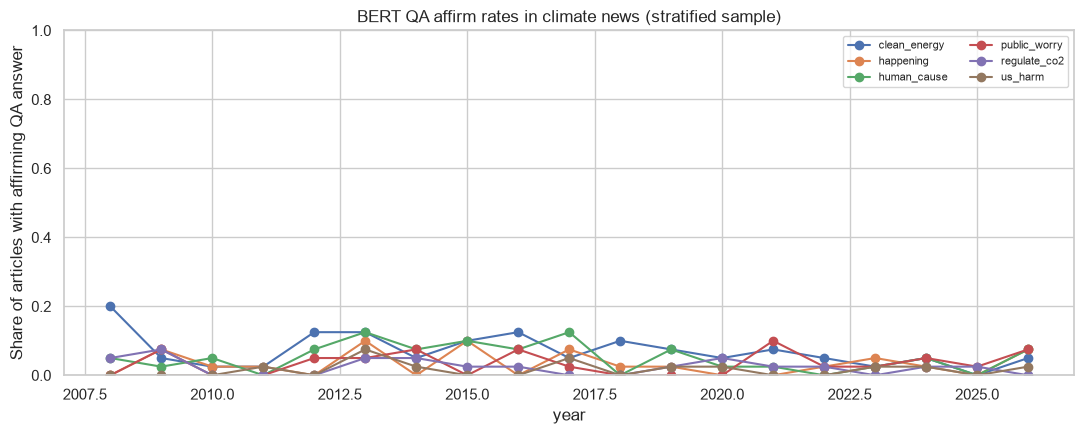

item,clean_energy,happening,human_cause,public_worry,regulate_co2,us_harm
year,,,,,,
2022,0.050,0.025,0.000,0.025,0.025,0.000
2023,0.025,0.050,0.025,0.025,0.000,0.025
2024,0.050,0.025,0.050,0.050,0.025,0.025
2025,0.000,0.000,0.000,0.025,0.025,0.000
2026,0.050,0.075,0.075,0.075,0.000,0.025


In [5]:
pivot = yearly.pivot(index="year", columns="item", values="affirm_rate")
fig, ax = plt.subplots(figsize=(11, 4.5))
pivot.plot(ax=ax, marker="o")
ax.set_ylim(0, 1)
ax.set_ylabel("Share of articles with affirming QA answer")
ax.set_title("BERT QA affirm rates in climate news (stratified sample)")
ax.legend(loc="best", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()
display(pivot.round(3).tail())

## Compare to CCAM (year-aligned)
CCAM is wave-based; we average waves within each calendar year for a coarse comparison to the yearly BERT series.

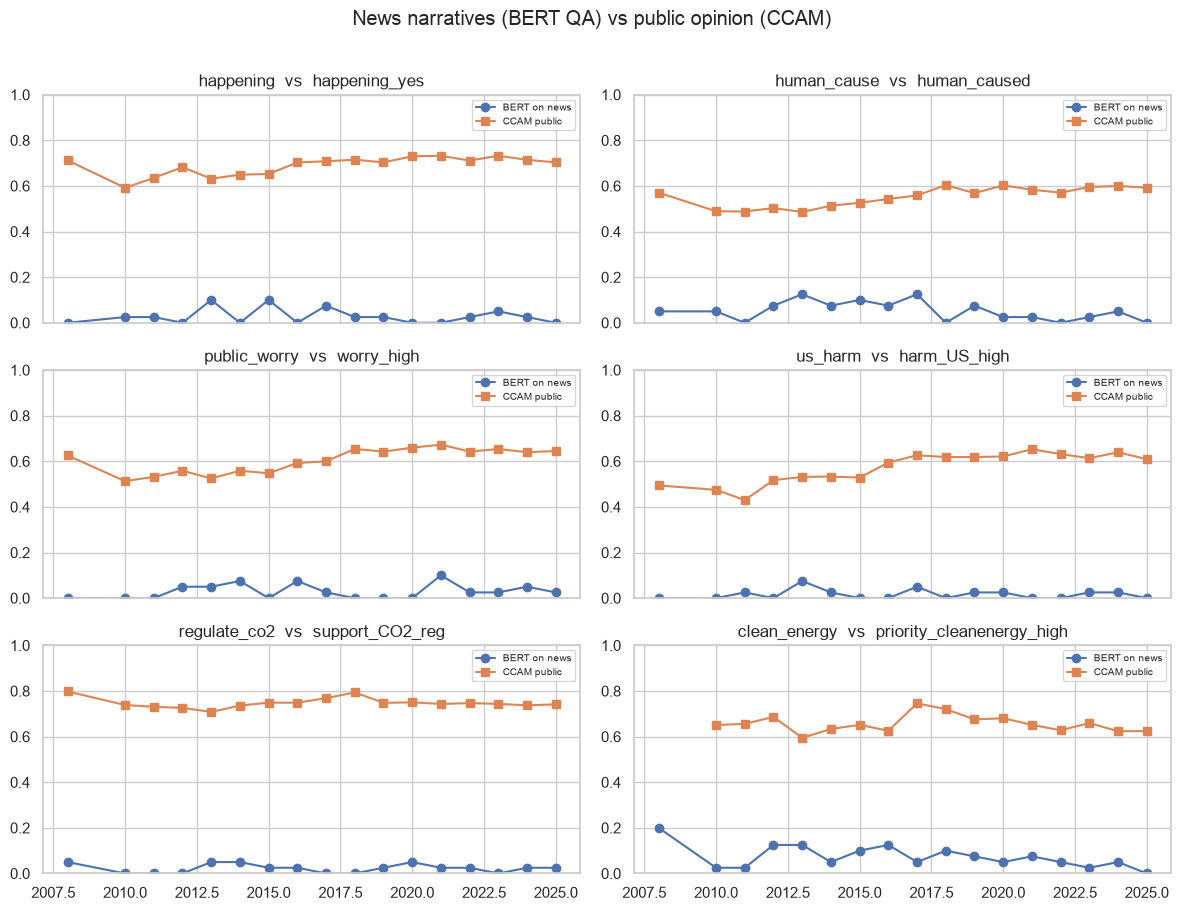

In [6]:
ccam = apply_recodes(pd.read_csv(CCAM_PATH, low_memory=False))
wave_out = wave_level_outcomes(ccam)

# Belief shares not in wave_level_outcomes — compute happening / human-caused by year
def weighted_share(df, col, values):
    s, w = df[col], df["weight_wave"]
    mask = s.notna() & w.notna() & ~s.astype(str).str.lower().eq("refused")
    if mask.sum() == 0:
        return float("nan")
    return float((w[mask] * s[mask].astype(str).isin(values).astype(float)).sum() / w[mask].sum())

belief_years = []
for year, g in ccam.groupby("year"):
    belief_years.append(
        {
            "year": int(year),
            "happening_yes": weighted_share(g, "happening", {"Yes"}),
            "human_caused": weighted_share(
                g, "cause_recoded", {"Caused mostly by human activities"}
            ),
        }
    )
belief_year = pd.DataFrame(belief_years)

ccam_year = (
    wave_out.assign(year=wave_out["wave_date"].dt.year)
    .groupby("year", as_index=False)[
        ["worry_high", "harm_US_high", "support_CO2_reg", "priority_cleanenergy_high"]
    ]
    .mean()
    .merge(belief_year, on="year", how="outer")
    .sort_values("year")
)

item_to_ccam = {
    "happening": "happening_yes",
    "human_cause": "human_caused",
    "public_worry": "worry_high",
    "us_harm": "harm_US_high",
    "regulate_co2": "support_CO2_reg",
    "clean_energy": "priority_cleanenergy_high",
}

fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
axes = axes.ravel()
for ax, (item, ccam_col) in zip(axes, item_to_ccam.items()):
    b = yearly[yearly["item"] == item][["year", "affirm_rate"]].rename(columns={"affirm_rate": "bert_news"})
    c = ccam_year[["year", ccam_col]].rename(columns={ccam_col: "ccam_public"})
    m = b.merge(c, on="year", how="inner")
    ax.plot(m["year"], m["bert_news"], marker="o", label="BERT on news")
    ax.plot(m["year"], m["ccam_public"], marker="s", label="CCAM public")
    ax.set_ylim(0, 1)
    ax.set_title(f"{item}  vs  {ccam_col}")
    ax.legend(fontsize=7)
fig.suptitle("News narratives (BERT QA) vs public opinion (CCAM)", y=1.01)
plt.tight_layout()
plt.show()

In [7]:
# Year-level correlations between BERT news affirm rates and CCAM
corr_rows = []
for item, ccam_col in item_to_ccam.items():
    b = yearly[yearly["item"] == item][["year", "affirm_rate"]]
    c = ccam_year[["year", ccam_col]]
    m = b.merge(c, on="year", how="inner").dropna()
    if len(m) < 5:
        r = float("nan")
    else:
        r = m["affirm_rate"].corr(m[ccam_col])
    corr_rows.append({"item": item, "ccam_outcome": ccam_col, "n_years": len(m), "pearson_r": r})
corr = pd.DataFrame(corr_rows).sort_values("pearson_r", ascending=False)
display(corr.style.format({"pearson_r": "{:.3f}"}))

print(
    """
Interpretation tips:
- Positive r: years when news more often affirms X, public CCAM measures also higher.
- Weak/negative r is common — media agenda ≠ opinion, and extractive QA is noisy.
- This is associational and year-aggregated; not causal.
"""
)

,item,ccam_outcome,n_years,pearson_r
2,public_worry,worry_high,17,0.053
5,clean_energy,priority_cleanenergy_high,16,0.011
3,us_harm,harm_US_high,17,0.005
4,regulate_co2,support_CO2_reg,17,-0.048
0,happening,happening_yes,17,-0.320
1,human_cause,human_caused,17,-0.455



Interpretation tips:
- Positive r: years when news more often affirms X, public CCAM measures also higher.
- Weak/negative r is common — media agenda ≠ opinion, and extractive QA is noisy.
- This is associational and year-aggregated; not causal.

